# 00 — yfinance sandbox

Starter notebook for `jarvis-quant` research-only mode. Loads parquet bars saved by `_pull_starter_data.py`.

**Symbols** (mapped to Amo's live trading focus):
- `ES=F` — E-mini S&P continuous (proxy for MES)
- `GC=F` — Gold continuous (proxy for MGC)
- `NQ=F` — Nasdaq continuous (proxy for MNQ)
- `SPY`, `QQQ` — equity reference

Data window: 2y daily, auto-adjust off (raw OHLC). Refresh by re-running `python research/_pull_starter_data.py`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path.cwd() / "data"
assert DATA.exists(), f"Run _pull_starter_data.py first. Expected {DATA}"

frames = {p.stem.replace('_1d', ''): pd.read_parquet(p) for p in sorted(DATA.glob('*_1d.parquet'))}
for name, df in frames.items():
    print(f"{name:6s}  {len(df):4d} rows  {df.index.min().date()} -> {df.index.max().date()}")

ES_F     504 rows  2024-05-06 -> 2026-05-06
GC_F     504 rows  2024-05-06 -> 2026-05-06
NQ_F     504 rows  2024-05-06 -> 2026-05-06
QQQ      501 rows  2024-05-07 -> 2026-05-06
SPY      501 rows  2024-05-07 -> 2026-05-06


## Inspect one symbol

In [2]:
es = frames['ES_F']
es.tail(10)

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,ES=F,ES=F,ES=F,ES=F,ES=F,ES=F
Date,,,,,,
2026-04-23,7143.50,7143.50,7181.50,7079.25,7163.00,1862446
2026-04-24,7194.75,7194.75,7200.50,7135.50,7143.00,1463962
2026-04-27,7206.00,7206.00,7211.25,7171.50,7185.00,1085690
2026-04-28,7171.00,7171.00,7223.25,7146.25,7204.75,1361467
2026-04-29,7168.00,7168.00,7190.75,7131.25,7172.50,1368362
2026-04-30,7243.75,7243.75,7253.50,7133.75,7150.00,1732392
2026-05-01,7258.00,7258.00,7300.75,7240.75,7256.00,1263615
2026-05-04,7230.25,7230.25,7279.75,7199.50,7276.25,1581015


## Normalized close — visual sanity check

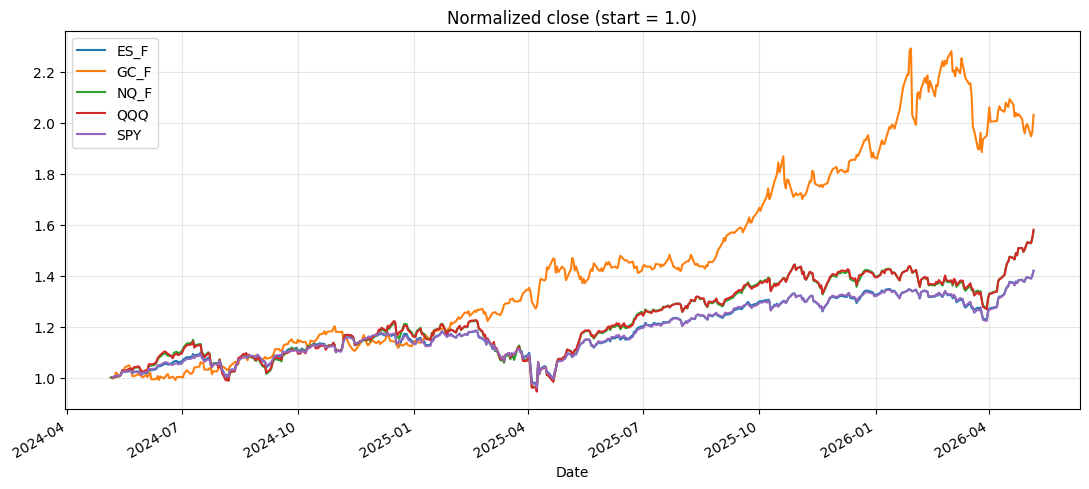

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, df in frames.items():
    close = df['Close'].squeeze()
    (close / close.iloc[0]).plot(ax=ax, label=name)
ax.set_title('Normalized close (start = 1.0)')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Daily-return correlation matrix

Sanity check that ES/SPY co-move (should be ~0.95+), ES/GC are weakly correlated, etc.

In [4]:
rets = pd.DataFrame({name: df['Close'].squeeze().pct_change() for name, df in frames.items()}).dropna()
corr = rets.corr()
print(corr.round(3))

       ES_F   GC_F   NQ_F    QQQ    SPY
ES_F  1.000  0.102  0.964  0.941  0.977
GC_F  0.102  1.000  0.109  0.110  0.103
NQ_F  0.964  0.109  1.000  0.980  0.944
QQQ   0.941  0.110  0.980  1.000  0.961
SPY   0.977  0.103  0.944  0.961  1.000


## Next steps (suggested)

1. Replace yfinance with IBKR historical bars (read-only `ib_async` calls — no orders) once you want intraday data. yfinance is daily-only and slightly stale; IBKR gives 1-min/5-min through your existing Gateway.
2. Move signal-prototyping code into `~/Code/jarvis-quant/src/signals/` once you have a working pattern, keeping the notebook for ad-hoc exploration only.
3. Pick a backtester when needed — `vectorbt` for vectorized cross-sectional, `backtrader` for event-driven single-asset. Defer the choice until the tutorial reaches that step or you have a concrete backtest to run.

In [5]:
print("hello from jarvis")

hello from jarvis
